**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 6**
Ingeniería de características (FE)

---

*   Equipo 67
*   NOMBRE: Adolfo Siliceo Vásquez, Héctor André Simental Gaxiola, Carlos Armando Solis Contreras, José Carlos Sierra Pérez   
*   MATRÍCULA: A01841467, A01840739, A01841611, A01055689

En esta actividad trabajarás con el archivo `computer_prices.csv`, basado en un conjunto de datos sobre características técnicas y especificaciones de computadoras portátiles y de escritorio, disponible en Kaggle.

Los datos fueron recopilados para analizar el rendimiento y el precio de los dispositivos, e incluyen información sobre hardware, almacenamiento, conectividad y otras especificaciones técnicas. Los indicadores incluidos son:

* `device_type`: Tipo de dispositivo (ej. laptop, desktop)
* `brand`: Marca del dispositivo
* `model`: Modelo del dispositivo
* `release_year`: Año de lanzamiento del dispositivo
* `os`: Sistema operativo instalado
* `form_factor`: Factor de forma o diseño del dispositivo (ej. laptop, ultrabook, desktop tower)
* `cpu_brand`: Marca del procesador
* `cpu_tier`: Nivel o gama del procesador, ordinal del 1 al 6 según desempeño
* `cpu_cores`: Número de núcleos del procesador
* `cpu_threads`: Número de hilos de ejecución del procesador
* `gpu_brand`: Marca de la tarjeta gráfica
* `gpu_model`: Modelo específico de la tarjeta gráfica
* `gpu_tier`: Nivel o gama de la GPU, ordinal del 1 al 6 según desempeño
* `vram_gb`: Memoria de video de la GPU en gigabytes
* `ram_gb`: Memoria RAM del dispositivo en gigabytes
* `storage_type`: Tipo de almacenamiento (ej. HDD, SSD)
* `storage_gb`: Capacidad de almacenamiento en gigabytes
* `storage_drive_count`: Número de unidades de almacenamiento instaladas
* `display_type`: Tipo de pantalla (ej. IPS, TN, OLED)
* `charger_watts`: Potencia del cargador (en watts) para laptops
* `psu_watts`: Potencia de la fuente de poder (en watts) para desktops
* `wifi`: Estándar de conectividad Wi-Fi (ej. Wi-Fi 5, 6, 6E, 7)
* `bluetooth`: Versión de Bluetooth
* `weight_kg`: Peso del dispositivo en kilogramos
* `warranty_months`: Meses de garantía del dispositivo
* `price`: Precio del dispositivo. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo.

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Instalar las bibliotecas necesarias
%pip install category_encoders


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\jose.sierra\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy.stats import probplot
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import FunctionTransformer, PowerTransformer
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from category_encoders.binary import BinaryEncoder

1. Descarga el archivo: `computer_prices.csv` y guarda, en un dataframe (`compu_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Elimina las variables:
  * `model`: Debido a su altísima cardinalidad, lo que dificulta su uso en análisis y modelado.
  * `cpu_model`: Además de su elevada cardinalidad, su información ya está representada de manera implícita en otras variables como: `cpu_tier`, `cpu_cores` y `cpu_threads`

In [3]:
compu_df = pd.read_csv('computer_prices.csv')
compu_df.info()

print("Numéricas:", compu_df.select_dtypes(include='number').shape[1])
print("Texto:    ", compu_df.select_dtypes(exclude='number').shape[1])
compu_df.nunique().sort_values(ascending=False)

compu_df = compu_df.drop(columns=['model', 'cpu_model'])
compu_df.shape

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 27 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   device_type          100000 non-null  str    
 1   brand                100000 non-null  str    
 2   model                100000 non-null  str    
 3   release_year         100000 non-null  int64  
 4   os                   100000 non-null  str    
 5   form_factor          100000 non-null  str    
 6   cpu_brand            100000 non-null  str    
 7   cpu_model            100000 non-null  str    
 8   cpu_tier             100000 non-null  int64  
 9   cpu_cores            100000 non-null  int64  
 10  cpu_threads          100000 non-null  int64  
 11  gpu_brand            100000 non-null  str    
 12  gpu_model            100000 non-null  str    
 13  gpu_tier             100000 non-null  int64  
 14  vram_gb              100000 non-null  int64  
 15  ram_gb               100000 n

(100000, 25)

2. Antes de iniciar con el análisis univariado, verifica si hay valores duplicados y/o faltantes.
* Obtén las estadísticas descriptivas, separado las numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Genera histogramas para las numéricas y diagramas de barras para las categóricas. Con alta cardinalidad, sólo incluye los 10 valores más frecuentes.

In [4]:
print(compu_df.duplicated().any())
print(compu_df.isna().any())

#Solo si hay algún True

print("Registros duplicados:", compu_df.duplicated().sum())
print("Valores faltantes:   ", compu_df.isna().sum().sum())

False
device_type            False
brand                  False
release_year           False
os                     False
form_factor            False
cpu_brand              False
cpu_tier               False
cpu_cores              False
cpu_threads            False
gpu_brand              False
gpu_model              False
gpu_tier               False
vram_gb                False
ram_gb                 False
storage_type           False
storage_gb             False
storage_drive_count    False
display_type           False
charger_watts          False
psu_watts              False
wifi                   False
bluetooth              False
weight_kg              False
warranty_months        False
price                  False
dtype: bool
Registros duplicados: 0
Valores faltantes:    0


In [5]:
num_cols = compu_df.select_dtypes(include='number').columns
cat_cols = compu_df.select_dtypes(exclude='number').columns

compu_df[num_cols].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
release_year,100000.0,2022.32,2.03,2018.00,2021.00,2023.00,2024.00,2025.00
cpu_tier,100000.0,3.15,1.37,1.00,2.00,3.00,4.00,6.00
cpu_cores,100000.0,10.52,5.04,4.00,6.00,8.00,14.00,28.00
cpu_threads,100000.0,19.37,9.72,4.00,12.00,16.00,24.00,56.00
gpu_tier,100000.0,2.99,1.46,1.00,2.00,3.00,4.00,6.00
vram_gb,100000.0,6.15,3.96,0.00,4.00,6.00,8.00,16.00
ram_gb,100000.0,39.71,31.90,8.00,16.00,32.00,64.00,144.00
storage_gb,100000.0,903.94,774.24,256.00,512.00,512.00,1024.00,4096.00
storage_drive_count,100000.0,1.52,0.80,1.00,1.00,1.00,2.00,4.00
charger_watts,100000.0,61.38,62.80,0.00,0.00,65.00,90.00,240.00


In [6]:
display(compu_df[cat_cols].describe().T)

for col in cat_cols:
    tabla = pd.DataFrame({
        'frecuencia': compu_df[col].value_counts(),
        'porcentaje': compu_df[col].value_counts(normalize=True).mul(100).round(2)
    })
    print(f"\n=== {col} ===")
    display(tabla)

,count,unique,top,freq
device_type,100000,2,Laptop,59844
brand,100000,10,Lenovo,15992
os,100000,4,Windows,71817
form_factor,100000,10,Mainstream,17819
cpu_brand,100000,3,Intel,52774
gpu_brand,100000,4,NVIDIA,54712
gpu_model,100000,49,Apple Integrated,18922
storage_type,100000,4,NVMe,45059
display_type,100000,6,LED,32000
wifi,100000,4,Wi-Fi 6,46149



=== device_type ===


,frecuencia,porcentaje
device_type,,
Laptop,59844,59.84
Desktop,40156,40.16



=== brand ===


,frecuencia,porcentaje
brand,,
Lenovo,15992,15.99
HP,14114,14.11
Dell,14005,14.00
Apple,11915,11.92
ASUS,10159,10.16
Acer,9925,9.93
Samsung,8066,8.07
MSI,7891,7.89
Gigabyte,4900,4.90


...

,frecuencia,porcentaje
storage_type,,
NVMe,45059,45.06
SSD,24937,24.94
HDD,15023,15.02
Hybrid,14981,14.98



=== display_type ===


,frecuencia,porcentaje
display_type,,
LED,32000,32.00
OLED,21910,21.91
IPS,17742,17.74
Mini-LED,12188,12.19
QLED,10069,10.07
VA,6091,6.09



=== wifi ===


,frecuencia,porcentaje
wifi,,
Wi-Fi 6,46149,46.15
Wi-Fi 6E,25923,25.92
Wi-Fi 5,19926,19.93
Wi-Fi 7,8002,8.00


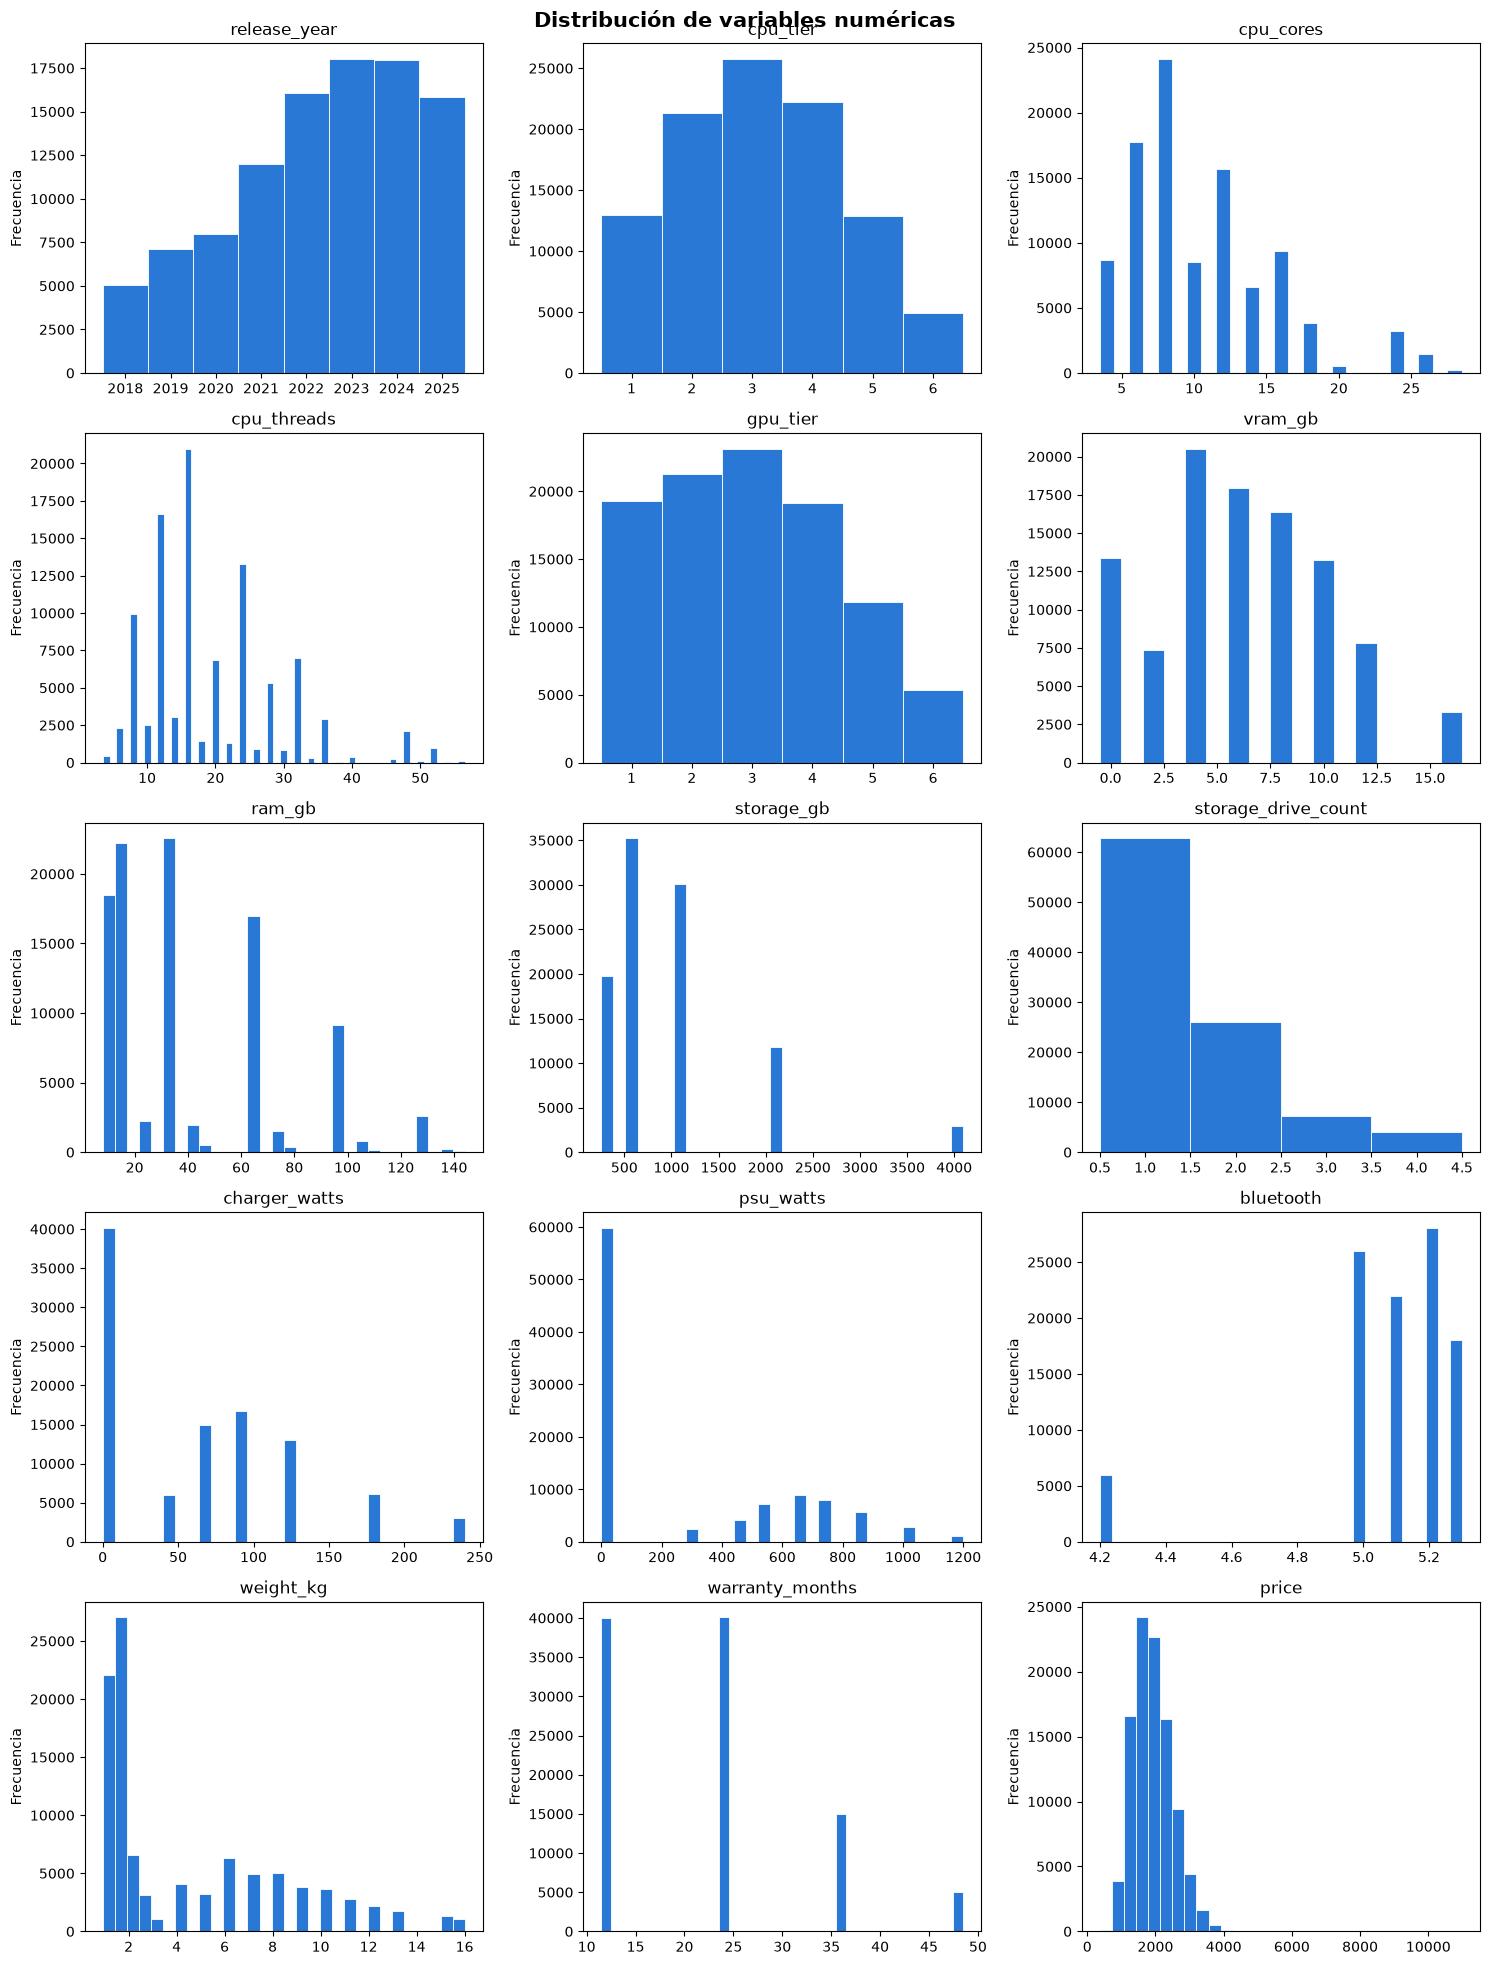

In [7]:
fig, axes = plt.subplots(5, 3, figsize=(15, 20))
for ax, col in zip(axes.flat, num_cols):
    s = compu_df[col]
    if pd.api.types.is_integer_dtype(s) and (s.max() - s.min()) <= 60:
        bins = np.arange(s.min(), s.max() + 2) - 0.5   # una barra por valor entero
    else:
        bins = 30
    ax.hist(s, bins=bins, color='#2a78d6', edgecolor='white', linewidth=0.6)
    ax.set_title(col)
    ax.set_ylabel('Frecuencia')
for ax in axes.flat[len(num_cols):]:
    ax.set_visible(False)
fig.suptitle('Distribución de variables numéricas', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

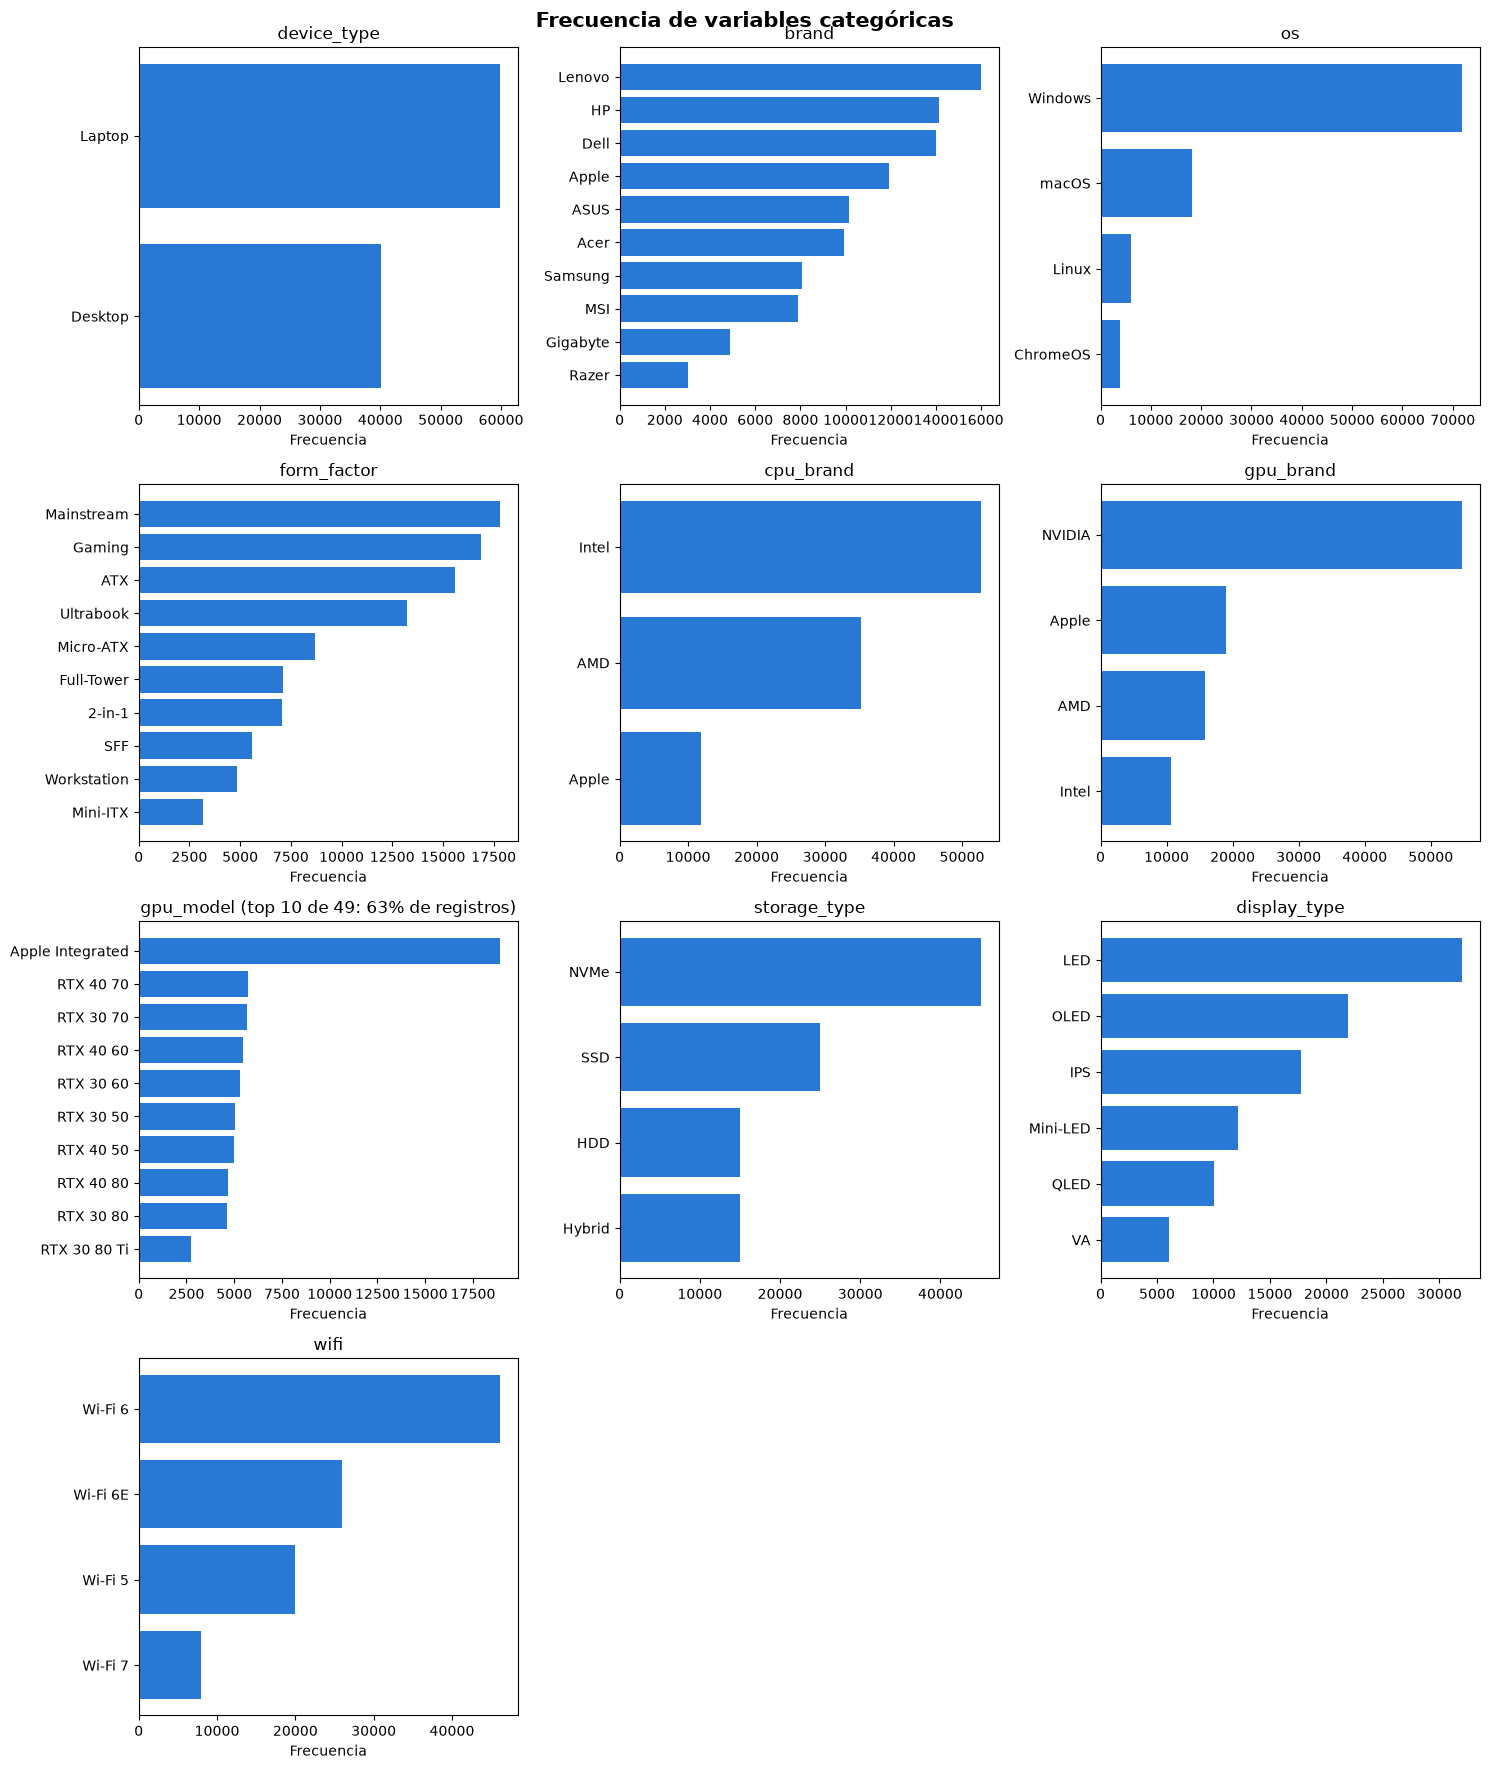

In [8]:
fig, axes = plt.subplots(4, 3, figsize=(15, 18))
for ax, col in zip(axes.flat, cat_cols):
    frec = compu_df[col].value_counts()
    top = frec.head(10)
    ax.barh(top.index[::-1], top.values[::-1], color='#2a78d6')
    if len(frec) > 10:
        ax.set_title(f'{col} (top 10 de {len(frec)}: {top.sum()/frec.sum():.0%} de registros)')
    else:
        ax.set_title(col)
    ax.set_xlabel('Frecuencia')
for ax in axes.flat[len(cat_cols):]:
    ax.set_visible(False)
fig.suptitle('Frecuencia de variables categóricas', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

3. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Reflexiona sobre cuáles variables, de las que se imprimieron, representan de manera general la capacidad del hardware y mantenlas; elimina las demás por aportar información redundante.
* Incluye una breve justificación de tus decisiones.

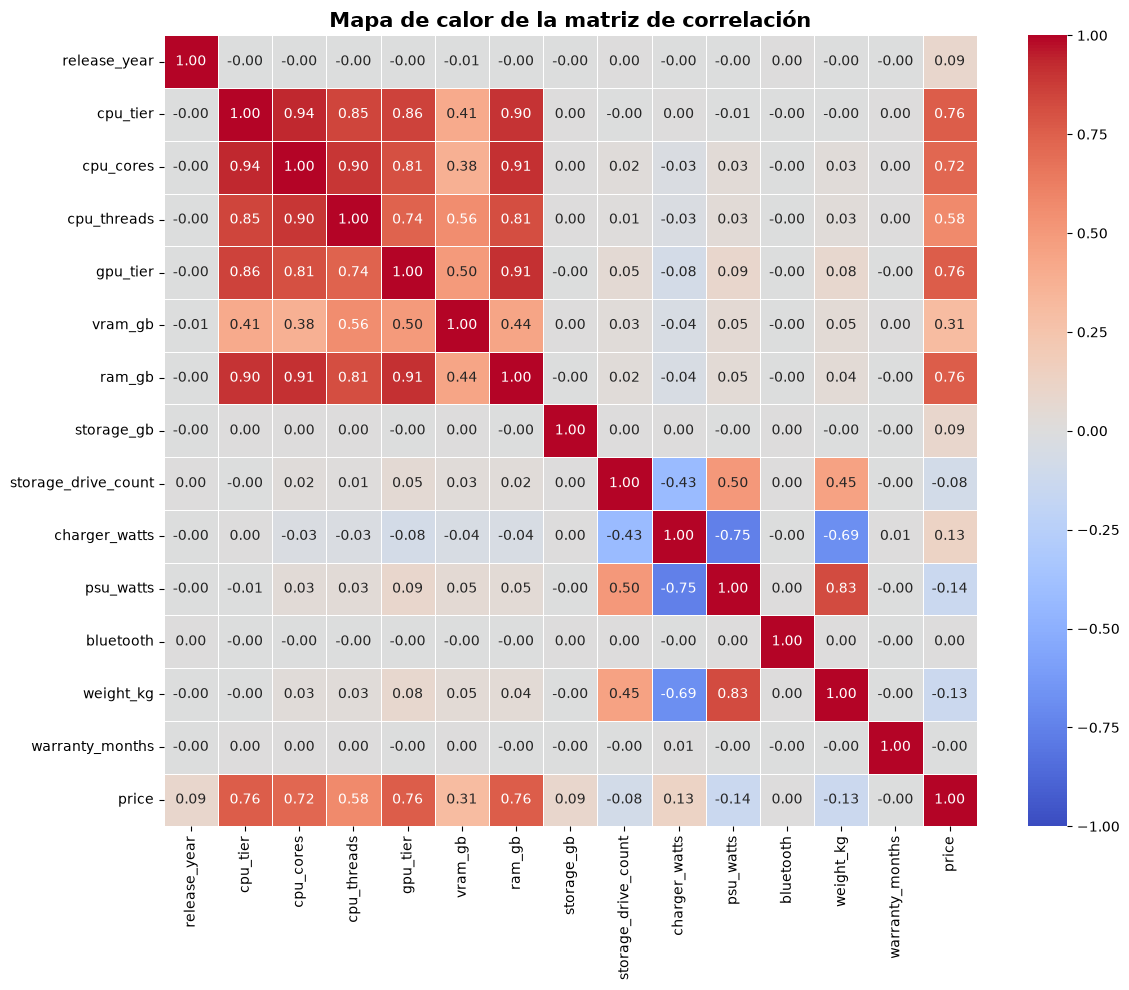

Pares de variables con correlación superior a 0.9:
- cpu_tier y cpu_cores: 0.9374
- cpu_cores y ram_gb: 0.9068
- gpu_tier y ram_gb: 0.9129


In [9]:
num_cols = compu_df.select_dtypes(include="number").columns
corr_matrix = compu_df[num_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Mapa de calor de la matriz de correlación', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

high_corr_pairs = []
columns = corr_matrix.columns
for i in range(len(columns)):
    for j in range(i + 1, len(columns)):
        val = corr_matrix.iloc[i, j]
        if abs(val) > 0.9:
            high_corr_pairs.append((columns[i], columns[j], val))

print("Pares de variables con correlación superior a 0.9:")
for var1, var2, corr_val in high_corr_pairs:
    print(f"- {var1} y {var2}: {corr_val:.4f}")



In [10]:
#Se eliminan las variables redundantes identificadas
compu_df = compu_df.drop(columns=['cpu_cores'])
print("\n")
print("Dimensiones actuales del DataFrame tras depurar redundancias:", compu_df.shape)



Dimensiones actuales del DataFrame tras depurar redundancias: (100000, 24)


--------------
Mantendremos cpu_tier y gpu_tier como representantes generales de la capacidad de procesamiento y gráfica, y eliminaremos cpu_cores (redundante con el nivel del procesador) por aportar información redundante.

Las variables tier (gama) ya encapsulan el rendimiento general del hardware de manera más limpia. Conservar múltiples métricas que miden basicamente lo mismo, ade mas de que no aporta mucho, podria genera problemas a la larga.
--------------

4. Para comenzar con la ingeniería de características, crea una copia del dataframe y asígnala a un nuevo objeto llamado `compu_transf`.
* Calcula cuántos años han pasado desde el lanzamiento de cada computadora y almacénalo en una nueva columna llamada `years_since_release`; luego, elimina la columna original.
* Utiliza `KBinsDiscretizer` para reemplazar la columna `vram_gb` en 4 bins ordinales basados en cuantiles.
* Imprime los valores que delimitan cada bin y haz un gráfico de barras para ver la cantidad de observaciones en cada uno, con el fin de entender cómo se agruparon los datos.



Valores que delimitan cada bin (límites de los cuantiles):
Límites para vram_gb: [ 0.  4.  6.  8. 16.]




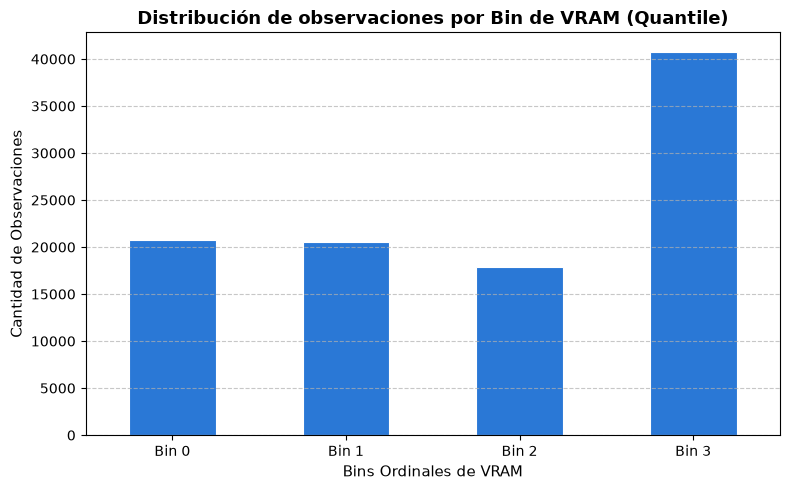

In [11]:
#Para comenzar con la transformación de variables sin afectar el conjunto de datos original, se crea una copia
#para cálculos temporales y discretización.
compu_transf = compu_df.copy()

current_year = 2026
compu_transf['years_since_release'] = current_year - compu_transf['release_year']

# Eliminar la columna original release_year
compu_transf = compu_transf.drop(columns=['release_year'])

# Utilizar KBinsDiscretizer para reemplazar vram_gb en 4 bins ordinales basados en cuantiles
est = KBinsDiscretizer(n_bins=4, encode='ordinal', strategy='quantile', quantile_method='linear')
compu_transf['vram_gb'] = est.fit_transform(compu_transf[['vram_gb']])

# Imprimir los valores que delimitan
print("\n")
print("Valores que delimitan cada bin (límites de los cuantiles):")
for i, edges in enumerate(est.bin_edges_):
    print(f"Límites para vram_gb: {edges}")
print("\n")

# Gráfico de barras para ver la cantidad de observaciones
bin_counts = compu_transf['vram_gb'].value_counts().sort_index()

plt.figure(figsize=(8, 5))
bin_counts.plot(kind='bar', color='#2a78d6', edgecolor='white', linewidth=0.8)
plt.title('Distribución de observaciones por Bin de VRAM (Quantile)', fontsize=13, fontweight='bold')
plt.xlabel('Bins Ordinales de VRAM', fontsize=11)
plt.ylabel('Cantidad de Observaciones', fontsize=11)
plt.xticks(ticks=range(4), labels=[f'Bin {int(i)}' for i in bin_counts.index], rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

--------------
Se crea compu_transf, se sustituye release_year por years_since_release y se agrupa vram_gb en cuatro intervalos. Las frecuencias permiten observar cómo se distribuyen los dispositivos entre los grupos.
--------------

5. Observa los histogramas del ejercicio 2. Notarás que en las variables `charger_watts` y `psu_watts` aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.
* Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada `power_watts` que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
* Por último, borra las columnas originales `charger_watts` y `psu_watts`.

Observa los histogramas del ejercicio 2. Notarás que en las variables charger_watts y psu_watts aparece una barra en 0. Analiza por qué ocurre esto y qué significa en relación con el tipo de dispositivo.

***Una laptop tiene batería y se alimenta por un cargador externo (45–240 W). No tiene fuente de poder interna, así que psu_watts = 0.***

***Un desktop tiene una fuente de poder interna (PSU, 300–1200 W) y se conecta directo a la corriente. No usa cargador, así que charger_watts = 0.***

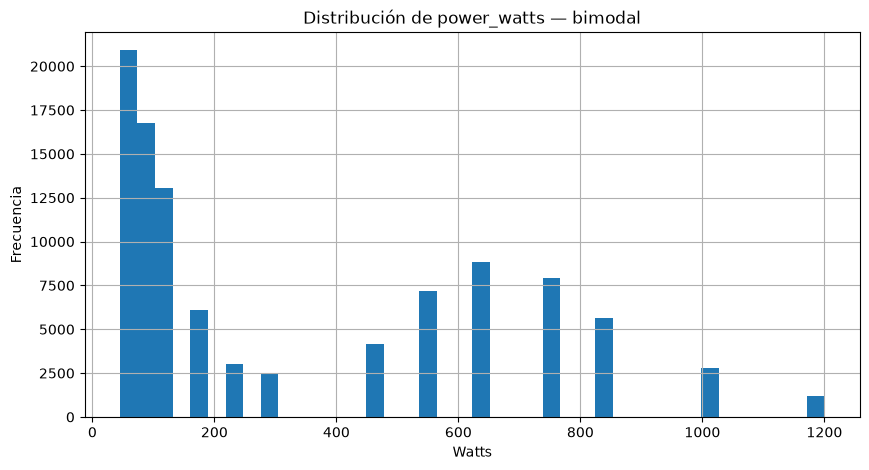

In [12]:
#Como estas variables son mutuamente excluyentes, combínalas en una nueva columna llamada power_watts que contenga la potencia correspondiente de cada dispositivo y, a continuación, haz un histograma para verificar que la distribución resultante es bimodal.
compu_transf['power_watts'] = compu_transf['charger_watts'] + compu_transf['psu_watts']


#Por último, borra las columnas originales charger_watts y psu_watts.
compu_transf = compu_transf.drop(columns=['charger_watts', 'psu_watts'])

compu_transf['power_watts'].hist(bins=40, figsize=(10, 5))
plt.title('Distribución de power_watts — bimodal')
plt.xlabel('Watts')
plt.ylabel('Frecuencia')
plt.show()

6. Para disminuir el sesgo de la variable `price`, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
* Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
* De la variable original y de cada una de las tres transformaciones se debe mostrar:
  * Histograma: para observar la distribución de los datos.
  * Boxplot: para identificar posibles valores atípicos.
  * Q-Q plot: para evaluar la normalidad de la variable.
  * Skew (sesgo): para cuantificar la asimetría de la distribución.
  * Cantidad de outliers: para conocer cuántos valores extremos existen.
* En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: `weight_kg`, `power_watts` y `price`.

In [13]:
#Para disminuir el sesgo de la variable price, crea tres transformadores: logaritmo, raíz cuadrada y Box - Cox.
log_t  = FunctionTransformer(np.log, inverse_func=np.exp)
sqrt_t = FunctionTransformer(np.sqrt, inverse_func=lambda x: x**2)
bc_t   = PowerTransformer(method='box-cox', standardize=False)

In [14]:
#Aplica cada transformador a la variable price, dejando el resultado en variables temporales. El objetivo es comparar los efectos de cada transformación antes de decidir cuál aplicar de manera definitiva sobre las variables continuas del dataframe.
price_log  = log_t.transform(compu_transf[['price']])
price_sqrt = sqrt_t.transform(compu_transf[['price']])
price_bc   = bc_t.fit_transform(compu_transf[['price']])

print('Lambda óptima de Box-Cox:', bc_t.lambdas_)

Lambda óptima de Box-Cox: [0.15041807]


In [15]:
##
def diagnostic_plots(datos, nombre):

    s = pd.Series(np.asarray(datos).ravel())

    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    s.hist(bins=40)
    plt.title(f'Histograma — {nombre}')

    plt.subplot(1, 3, 2)
    plt.boxplot(s, showmeans=True)
    plt.title(f'Boxplot — {nombre}')

    plt.subplot(1, 3, 3)
    probplot(s, dist='norm', plot=plt)
    plt.title(f'Q-Q plot — {nombre}')

    plt.tight_layout()
    plt.show()

    Q1, Q3 = s.quantile(0.25), s.quantile(0.75)
    IQR = Q3 - Q1
    BM = (s > Q3 + 1.5 * IQR) | (s < Q1 - 1.5 * IQR)

    print(f'{nombre}  ->  sesgo: {s.skew():.4f}   |   curtosis: {s.kurt():.4f}   |   outliers: {BM.sum()}')
    print('-' * 70)

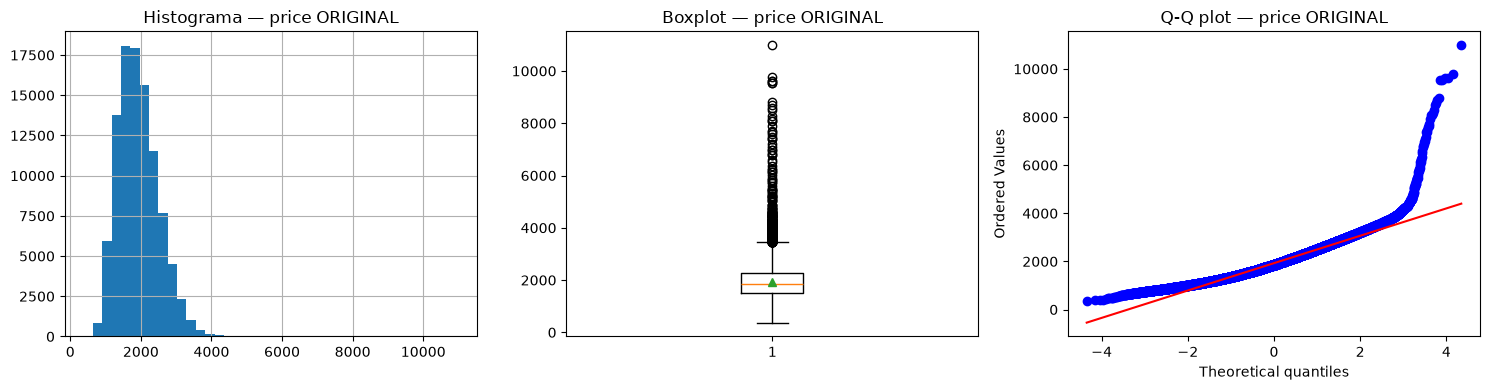

price ORIGINAL  ->  sesgo: 0.9866   |   curtosis: 4.8914   |   outliers: 976
----------------------------------------------------------------------


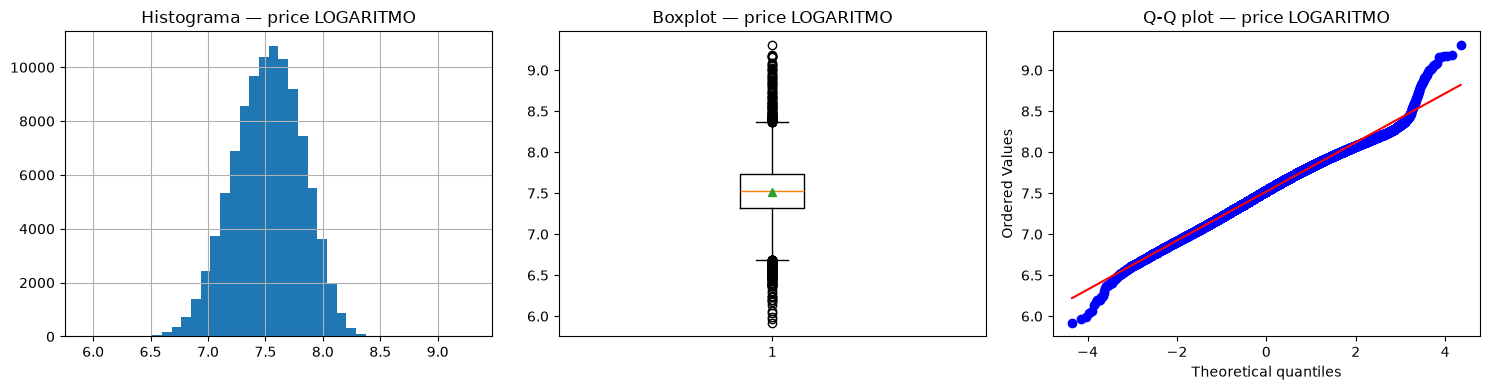

price LOGARITMO  ->  sesgo: -0.1331   |   curtosis: -0.0345   |   outliers: 386
----------------------------------------------------------------------


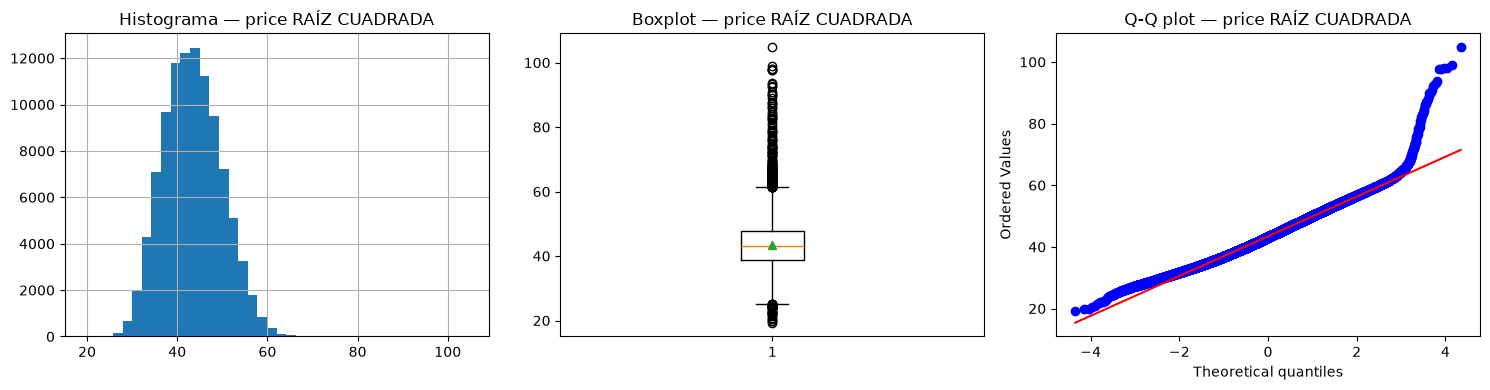

price RAÍZ CUADRADA  ->  sesgo: 0.3323   |   curtosis: 0.6415   |   outliers: 364
----------------------------------------------------------------------


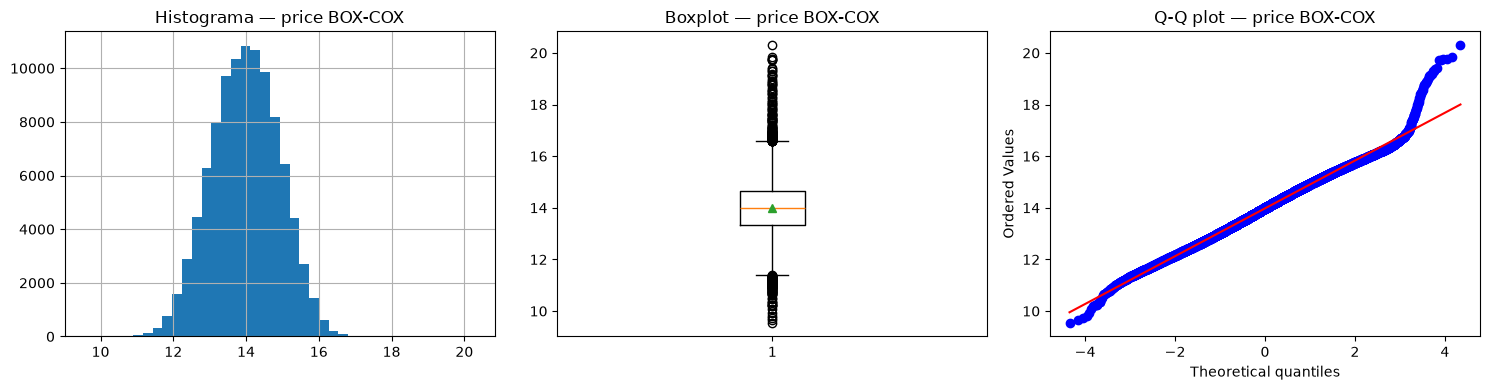

price BOX-COX  ->  sesgo: -0.0002   |   curtosis: 0.0091   |   outliers: 317
----------------------------------------------------------------------


In [16]:
#De la variable original y de cada una de las tres transformaciones se debe mostrar...
diagnostic_plots(compu_transf['price'], 'price ORIGINAL')
diagnostic_plots(price_log,  'price LOGARITMO')
diagnostic_plots(price_sqrt, 'price RAÍZ CUADRADA')
diagnostic_plots(price_bc,   'price BOX-COX')

In [17]:
#En función de los resultados obtenidos al comparar las transformaciones, decide cuál logró el mejor efecto sobre la distribución de la variable y aplícala directamente en el dataframe, reemplazando las variables continuas: weight_kg, power_watts y price.

cols_continuas = ['weight_kg', 'power_watts', 'price']

bc_final = PowerTransformer(method='box-cox', standardize=False)
compu_transf[cols_continuas] = bc_final.fit_transform(compu_transf[cols_continuas])

print('Lambdas por variable:')
for col, lam in zip(cols_continuas, bc_final.lambdas_):
    print(f'  {col:14s}  λ = {lam:.4f}')

Lambdas por variable:
  weight_kg       λ = -0.4804
  power_watts     λ = -0.1650
  price           λ = 0.1504


***la transformación seleccionada para aplicarse de manera definitiva es Box-Cox, podemos observar que el sesgo es prácticamente cero (-0.0002) y a curtosis es de 0.0091***

7. Para que todas las variables numéricas estén en la misma escala, aplica `MinMaxScaler` de sklearn a todas las columnas numéricas del dataframe, reemplazando las columnas originales.

In [18]:
num_cols = compu_transf.select_dtypes(include='number').columns

scaler = MinMaxScaler()
compu_transf[num_cols] = scaler.fit_transform(compu_transf[num_cols])

compu_transf[num_cols].describe().T[['min', 'mean', 'max']]

,min,mean,max
cpu_tier,0.0,0.430698,1.0
cpu_threads,0.0,0.295629,1.0
gpu_tier,0.0,0.398270,1.0
vram_gb,0.0,0.595883,1.0
ram_gb,0.0,0.233135,1.0
storage_gb,0.0,0.168733,1.0
storage_drive_count,0.0,0.174993,1.0
bluetooth,0.0,0.804331,1.0
weight_kg,0.0,0.517032,1.0
warranty_months,0.0,0.283343,1.0


8. Aunque `wifi` es una variable categórica, sus categorías tienen un orden natural (Wi-Fi 5 < Wi-Fi 6 < Wi-Fi 6E < Wi-Fi 7). Codifícala usando `OrdinalEncoder`.
* Luego, escala la variable codificada entre 0 y 1 con `MinMaxScaler`, para que quede en la misma escala que las variables numéricas del dataframe.

Nota: Ambos cambios deben efectuarse sobre la columna original, de manera que quede una única columna `wifi` con toda la información transformada.

In [19]:
orden_wifi = [['Wi-Fi 5', 'Wi-Fi 6', 'Wi-Fi 6E', 'Wi-Fi 7']]
ord_enc = OrdinalEncoder(categories=orden_wifi)
compu_transf['wifi'] = ord_enc.fit_transform(compu_transf[['wifi']])

wifi_scaler = MinMaxScaler()
compu_transf['wifi'] = wifi_scaler.fit_transform(compu_transf[['wifi']])

compu_transf[['wifi']].describe().T[['min', 'mean', 'max']]

,min,mean,max
wifi,0.0,0.40667,1.0


9. La variable `gpu_model` tiene muchas categorías. Usar *One-Hot Encoding* aumentaría significativamente la dimensionalidad del dataframe. Por ello, utiliza `BinaryEncoder` para codificarla.
* Guarda el resultado en un dataframe llamado `bin_df`. Más adelante, lo combinarás con `compu_transf` para integrar las variables codificadas.

In [ ]:
# Pregunta 9: codificación binaria de gpu_model
binary_encoder = BinaryEncoder(cols=['gpu_model'])
bin_df = binary_encoder.fit_transform(compu_transf[['gpu_model']])

print('Categorías originales de gpu_model:', compu_transf['gpu_model'].nunique())
print('Columnas binarias generadas:', bin_df.shape[1])
display(bin_df.head())

10. Usa `OneHotEncoder` para codificar las variables categóricas restantes. Asegúrate de usar `drop='first'` para evitar la multicolinealidad y guarda el resultado en un dataframe llamado `ohe_df`
* Combina el dataframe `compu_transf` con las variables categóricas que fueron codificadas en `bin_df` y `ohe_df`. No olvides eliminar las variables originales.
* Usa `describe()` sobre el dataframe resultante para corroborar que todas las columnas estén escaladas entre 0 y 1 y que no queden variables categóricas sin codificar.

In [ ]:
# Pregunta 10: One-Hot Encoding de las categorías restantes
cat_cols = compu_transf.select_dtypes(include=['object', 'category', 'string']).columns.drop('gpu_model')
ohe_encoder = OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore', dtype=int)
ohe_array = ohe_encoder.fit_transform(compu_transf[cat_cols])
ohe_df = pd.DataFrame(ohe_array, columns=ohe_encoder.get_feature_names_out(cat_cols), index=compu_transf.index)

# Integrar codificaciones y retirar las columnas originales
compu_transf = pd.concat([compu_transf.drop(columns=['gpu_model', *cat_cols]), bin_df, ohe_df], axis=1)

print('Columnas categóricas codificadas:', list(cat_cols))
print('Dimensiones del dataframe final:', compu_transf.shape)
print('Columnas no numéricas restantes:', compu_transf.select_dtypes(exclude='number').columns.tolist())
display(compu_transf.describe().T)
print('Todas las columnas entre 0 y 1:', bool(((compu_transf.min() >= 0) & (compu_transf.max() <= 1)).all()))

**Conclusiones de las preguntas 9 y 10**

En la pregunta 9 se aplica `BinaryEncoder` a `gpu_model`, que tiene alta cardinalidad, para representar sus categorías mediante un número reducido de columnas binarias sin crear una columna por cada modelo.

En la pregunta 10 se utiliza `OneHotEncoder(drop='first')` para las demás variables categóricas que aún permanecen en `compu_transf`. Se excluye `gpu_model` porque ya se codificó en la pregunta anterior, y `wifi` porque fue transformada a una variable numérica ordinal en la pregunta 8. Finalmente, se unen las columnas codificadas, se eliminan las originales y se comprueba que el resultado solo contiene números entre 0 y 1. El número exacto de columnas se muestra al ejecutar la libreta.

---

**Declaración de uso de IA (preguntas 9 y 10)**

OpenAI. (2026). *ChatGPT (GPT-6)* [Modelo de lenguaje grande], utilizado como apoyo para generación de código y redacción de conclusiones. https://chatgpt.com/